# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [2]:
brut = pd.read_csv("donnees/consommation_brut.csv")
print("Forme :", brut.shape)
print("\nTypes :\n", brut.dtypes)
print("\nManquants :\n", brut.isna().sum())
print("\nLignes en double :", brut.duplicated().sum())

Forme : (300, 4)

Types :
 mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Manquants :
 mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [3]:
print(brut["quartier"].nunique(), "écritures pour 12 quartiers")


43 écritures pour 12 quartiers


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [4]:
converti = pd.to_numeric(brut["kwh"], errors="coerce")

problemes = brut.loc[converti.isna() & brut["kwh"].notna(), "kwh"]
print(len(problemes), "valeurs non convertibles")
problemes.head(15)

52 valeurs non convertibles


0     184410 kWh
4     206280 kWh
9     215140 kWh
13       251 900
21    274520 kWh
27    301740 kWh
36    233010 kWh
43    155930 kWh
51    212510 kWh
53    424110 kWh
55    299610 kWh
58       373 880
59    333670 kWh
62    597730 kWh
66    456060 kWh
Name: kwh, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [5]:
propre = brut.copy()
propre["kwh"] = (
    propre["kwh"]
    .str.replace("kwh", "", case=False, regex=False)
    .str.replace(r"\s", "", regex=True)    
)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
print("Manquants restants :", propre["kwh"].isna().sum())
print(propre["kwh"].dtype)

Manquants restants : 9
float64


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [6]:
quartiers = pd.read_csv("donnees/quartiers.csv")

def normaliser(serie):
    return serie.str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

noms_officiels = dict(zip(normaliser(quartiers["quartier"]), quartiers["quartier"]))
propre["quartier"] = normaliser(propre["quartier"]).map(noms_officiels)

print("Noms perdus par map :", propre["quartier"].isna().sum())
print("Quartiers distincts :", propre["quartier"].nunique())

Noms perdus par map : 0
Quartiers distincts : 12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [7]:
print("Avant :", propre.shape)
propre = propre.drop_duplicates()
print("Après doublons :", propre.shape)
propre = propre.dropna(subset=["kwh"])
print("Après manquants :", propre.shape)
propre = propre.reset_index(drop=True)

Avant : (300, 4)
Après doublons : (288, 4)
Après manquants : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [8]:
mediane_quartier = propre.groupby("quartier")["kwh"].transform("median")
aberrants = propre["kwh"] > 3 * mediane_quartier

print(propre.loc[aberrants, ["mois", "quartier", "kwh"]])

propre.loc[aberrants, "kwh"] = propre.loc[aberrants, "kwh"] / 10
print("\nRelevés corrigés :", aberrants.sum())
print("Maximum de kwh :", propre["kwh"].max())

        mois        quartier        kwh
82   2025-02       Delmas 33  3602600.0
127  2025-02       Delmas 75  2012700.0
187  2024-02  Morne Calvaire  1439200.0
232  2024-01          Rue 15   997700.0

Relevés corrigés : 4
Maximum de kwh : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [9]:
reference = pd.read_csv("donnees/consommation.csv")
reference = reference[propre.columns].reset_index(drop=True)

print(propre.shape, reference.shape)

print(propre.equals(reference.astype(propre.dtypes.to_dict())))

(279, 4) (288, 4)
False


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [10]:
n_avant = len(propre)
avec_type = propre.merge(quartiers, on="quartier", how="left")
print("Lignes :", n_avant, "->", len(avec_type))
print("Quartiers sans correspondance :", avec_type["commune"].isna().sum())

avec_type["kwh_par_abonne"] = (avec_type["kwh"] / avec_type["abonnes"]).round(1)
avec_type["annee"] = pd.to_datetime(avec_type["mois"]).dt.year

avec_type[(avec_type["quartier"] == "Bas-Peu-de-Chose") & (avec_type["mois"] == "2024-01")]

Lignes : 279 -> 279
Quartiers sans correspondance : 0


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [11]:
meteo = pd.read_csv("donnees/meteo.csv")

n_avant = len(avec_type)
avec_meteo = avec_type.merge(meteo, on=["mois", "commune"], how="left")
print("Lignes :", n_avant, "->", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Lignes : 279 -> 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [12]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

relu = pd.read_csv("donnees/consommation_propre.csv")
print(relu.shape)
relu.head()

(279, 11)


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930.0,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560.0,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730.0,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280.0,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


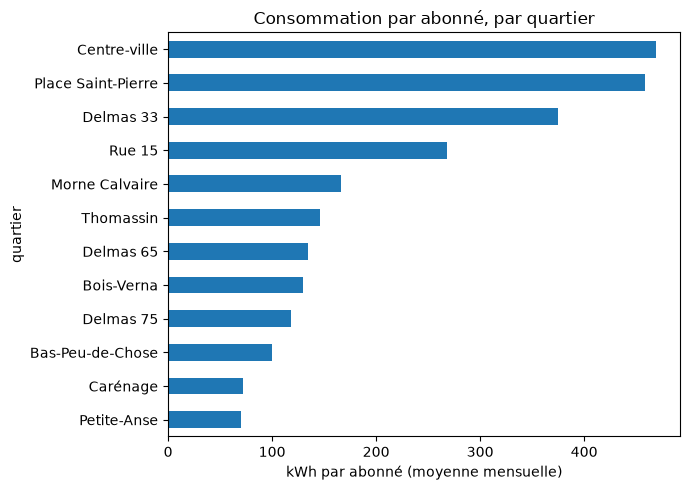

In [13]:
df = relu

print(df.groupby("type")["kwh_par_abonne"].mean().round(1))

classement = df.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)
print()
print(classement)

classement.sort_values().plot(kind="barh", figsize=(7, 5))
plt.xlabel("kWh par abonné (moyenne mensuelle)")
plt.title("Consommation par abonné, par quartier")
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

In [14]:
par_commune = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")

par_commune["hausse_pct"] = ((par_commune[2025] / par_commune[2024] - 1) * 100).round(1)
par_commune[[2024, 2025]] = (par_commune[[2024, 2025]] / 1e6).round(2)

par_commune = par_commune.sort_values("hausse_pct", ascending=False)
print("Consommation totale (millions de kWh) et hausse 2024 -> 2025 :")
par_commune

Consommation totale (millions de kWh) et hausse 2024 -> 2025 :


annee,2024,2025,hausse_pct
commune,,,
Cap-Haïtien,4.59,5.62,22.5
Pétion-Ville,8.60,9.68,12.6
Port-au-Prince,10.09,10.31,2.3
Delmas,11.61,11.74,1.1


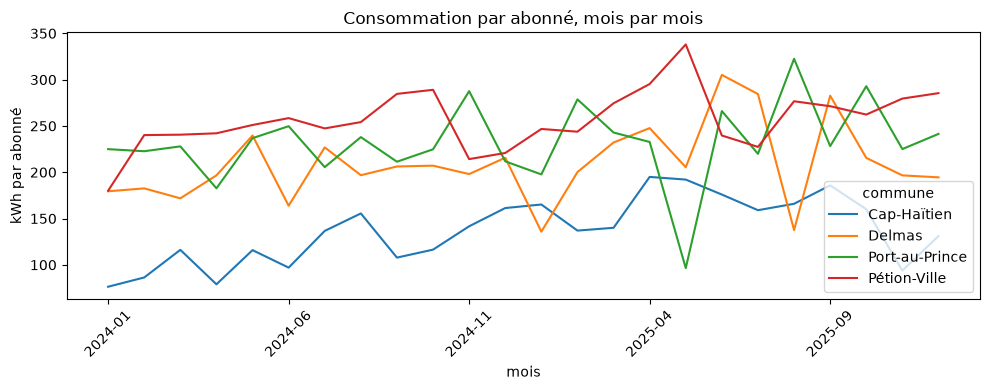

In [15]:
courbes = df.pivot_table(index="mois", columns="commune", values="kwh_par_abonne", aggfunc="mean")

courbes.plot(figsize=(10, 4))
plt.ylabel("kWh par abonné")
plt.title("Consommation par abonné, mois par mois")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

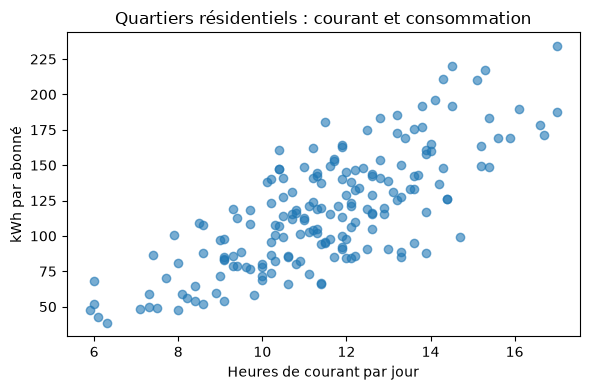

Corrélation avec les heures de courant : 0.76
Corrélation avec la température        : -0.15


In [16]:
residentiel = df[df["type"] == "Résidentiel"]

plt.figure(figsize=(6, 4))
plt.scatter(residentiel["heures_courant"], residentiel["kwh_par_abonne"], alpha=0.6)
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.title("Quartiers résidentiels : courant et consommation")
plt.tight_layout()
plt.show()

corr_courant = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_temp = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])
print("Corrélation avec les heures de courant :", round(corr_courant, 2))
print("Corrélation avec la température        :", round(corr_temp, 2))

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

In [17]:
stats = df.groupby("commune")["heures_courant"].agg(
    mediane="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
).round(1)
stats

,mediane,q1,q3
commune,,,
Cap-Haïtien,10.0,8.3,11.7
Delmas,11.9,10.1,13.0
Port-au-Prince,11.6,10.7,13.1
Pétion-Ville,11.6,10.4,13.0


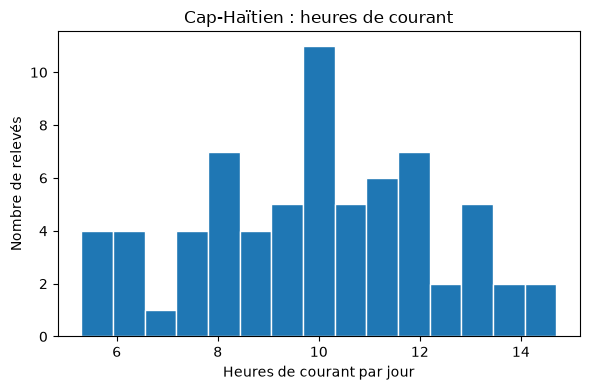

In [18]:
cap = df[df["commune"] == "Cap-Haïtien"]

plt.figure(figsize=(6, 4))
plt.hist(cap["heures_courant"], bins=15, edgecolor="white")
plt.xlabel("Heures de courant par jour")
plt.ylabel("Nombre de relevés")
plt.title("Cap-Haïtien : heures de courant")
plt.tight_layout()
plt.show()

In [19]:
faibles = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
print(len(faibles), "relevés de 2025 avec moins de 8 heures de courant")
faibles[["mois", "quartier", "commune", "heures_courant"]]

3 relevés de 2025 avec moins de 8 heures de courant


,mois,quartier,commune,heures_courant
81,2025-01,Delmas 33,Delmas,7.4
227,2025-08,Carénage,Cap-Haïtien,7.3
253,2025-11,Rue 15,Cap-Haïtien,5.9


**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [20]:
df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780.0
56,2024-11,Centre-ville,Commercial,597730.0
88,2025-09,Delmas 33,Commercial,591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

Dans les quartiers résidentiels, la consommation par abonné suit les heures de courant (corrélation de 0.76) et non la chaleur (-0.15 avec la température). Les coupures sont les plus longues à Cap-Haïtien (médiane de 10.0 heures contre 11.6 à 11.9 ailleurs), et la consommation y a le plus augmenté (+22.4 %). Une corrélation ne prouve pas une cause : elle montre que deux séries varient ensemble, pas que l'une provoque l'autre, et d'autres facteurs (type de quartier, revenus, appareils) peuvent jouer.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.